Epoch 1/3
211/211 ━━━━━━━━━━━━━━━━━━━━ 46s 184ms/step - accuracy: 0.7824 - loss: 0.6000 - val_accuracy: 0.8480 - val_loss: 0.4253
Epoch 2/3
211/211 ━━━━━━━━━━━━━━━━━━━━ 34s 152ms/step - accuracy: 0.8700 - loss: 0.3646 - val_accuracy: 0.8807 - val_loss: 0.3404
Epoch 3/3
211/211 ━━━━━━━━━━━━━━━━━━━━ 41s 152ms/step - accuracy: 0.8882 - loss: 0.3135 - val_accuracy: 0.8877 - val_loss: 0.3087

Classifier Test Accuracy:
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8855 - loss: 0.3246


/tmp/ipykernel_1564/3937148755.py:140: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = sqrtm(sigma1 @ sigma2)



VAE Class Distribution: [165  82  14   4  17   0 239 237  71 171]
GAN Class Distribution: [ 67  23  20  51 292  98 131  39 199  80]

GENERATIVE MODEL COMPARISON


,Metric,VAE,GAN
0,Inception Score,2.0101,3.2444
1,IS Standard Deviation,0.0769,0.0912
2,FID,121.9260,29.4522
3,Feature Diversity,5.1435,10.5480


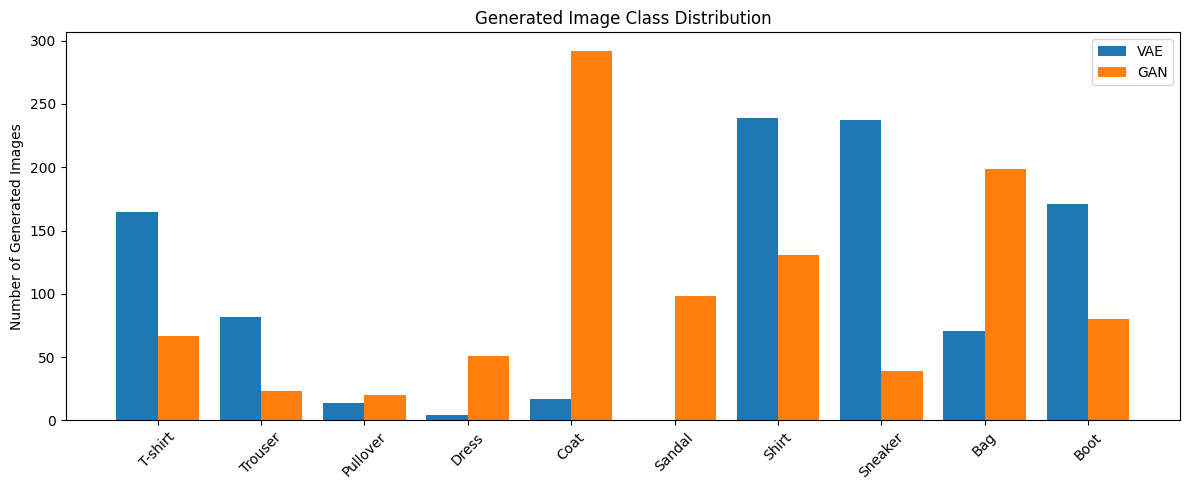

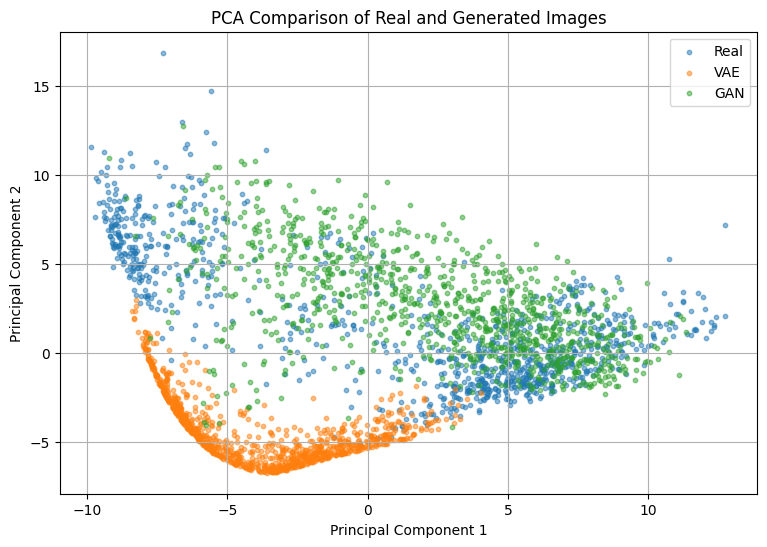

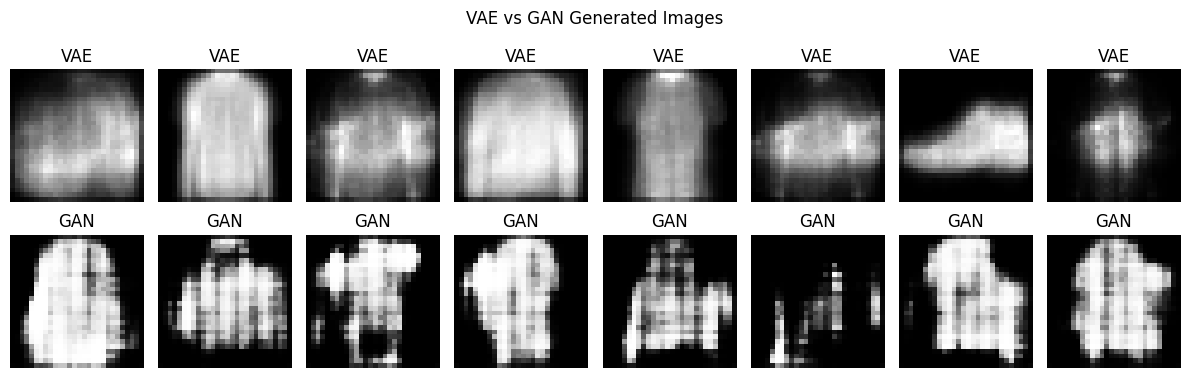


MODEL RECOMMENDATION
GAN has a lower FID and better feature-distribution similarity.
Compare IS, FID, diversity and class distribution before selecting a model.


In [24]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import sqrtm
from sklearn.decomposition import PCA
from tensorflow.keras import layers, Model

np.random.seed(42)
tf.random.set_seed(42)

# Load Fashion-MNIST
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

# Load trained generators from Experiment 29
vae_generator = tf.keras.models.load_model(
    "/content/vae_generator.keras"
)

gan_generator = tf.keras.models.load_model(
    "/content/gan_generator.keras"
)

# Generate 1000 samples from each model
vae_latent = np.random.normal(
    size=(1000, 2)
).astype("float32")

gan_noise = np.random.normal(
    size=(1000, 100)
).astype("float32")

vae_samples = vae_generator.predict(
    vae_latent, verbose=0
)

gan_samples = gan_generator.predict(
    gan_noise, verbose=0
)

# Train Fashion-MNIST classifier
classifier_input = layers.Input(shape=(28, 28, 1))

x = layers.Conv2D(32, 3, activation="relu", padding="same")(classifier_input)
x = layers.MaxPooling2D()(x)

x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
x = layers.MaxPooling2D()(x)

x = layers.Flatten()(x)
features = layers.Dense(128, activation="relu", name="features")(x)
output = layers.Dense(10, activation="softmax")(features)

classifier = Model(classifier_input, output)

classifier.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

classifier.fit(
    x_train[:30000],
    y_train[:30000],
    epochs=3,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

print("\nClassifier Test Accuracy:")
classifier.evaluate(x_test, y_test, verbose=1)

# Feature extraction model
feature_model = Model(
    classifier.input,
    classifier.get_layer("features").output
)

# Classifier predictions
vae_probs = classifier.predict(vae_samples, verbose=0)
gan_probs = classifier.predict(gan_samples, verbose=0)

real_probs = classifier.predict(
    x_test[:1000], verbose=0
)

# Inception Score
def inception_score(probs, splits=5):
    scores = []

    for part in np.array_split(probs, splits):
        marginal = np.mean(part, axis=0)

        kl = part * (
            np.log(part + 1e-10) -
            np.log(marginal + 1e-10)
        )

        score = np.exp(np.mean(np.sum(kl, axis=1)))
        scores.append(score)

    return np.mean(scores), np.std(scores)

vae_is, vae_is_std = inception_score(vae_probs)
gan_is, gan_is_std = inception_score(gan_probs)

# Extract features for FID
real_features = feature_model.predict(
    x_test[:1000], verbose=0
)

vae_features = feature_model.predict(
    vae_samples, verbose=0
)

gan_features = feature_model.predict(
    gan_samples, verbose=0
)

# FID calculation
def calculate_fid(real, generated):
    mu1 = np.mean(real, axis=0)
    mu2 = np.mean(generated, axis=0)

    sigma1 = np.cov(real, rowvar=False)
    sigma2 = np.cov(generated, rowvar=False)

    diff = mu1 - mu2

    covmean = sqrtm(sigma1 @ sigma2)

    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = (
        np.sum(diff ** 2) +
        np.trace(sigma1 + sigma2 - 2 * covmean)
    )

    return float(fid)

vae_fid = calculate_fid(real_features, vae_features)
gan_fid = calculate_fid(real_features, gan_features)

# Diversity: mean pairwise feature distance
def calculate_diversity(features):
    features = features[:500]

    distances = np.linalg.norm(
        features[:, None, :] - features[None, :, :],
        axis=2
    )

    return np.sum(distances) / (
        len(features) * (len(features) - 1)
    )

vae_diversity = calculate_diversity(vae_features)
gan_diversity = calculate_diversity(gan_features)

# Predicted class distribution
vae_classes = np.argmax(vae_probs, axis=1)
gan_classes = np.argmax(gan_probs, axis=1)

vae_distribution = np.bincount(
    vae_classes, minlength=10
)

gan_distribution = np.bincount(
    gan_classes, minlength=10
)

print("\nVAE Class Distribution:", vae_distribution)
print("GAN Class Distribution:", gan_distribution)

# Display comparison table
results = pd.DataFrame({
    "Metric": [
        "Inception Score",
        "IS Standard Deviation",
        "FID",
        "Feature Diversity"
    ],
    "VAE": [
        vae_is,
        vae_is_std,
        vae_fid,
        vae_diversity
    ],
    "GAN": [
        gan_is,
        gan_is_std,
        gan_fid,
        gan_diversity
    ]
})

print("\nGENERATIVE MODEL COMPARISON")
display(results.round(4))

# Plot class distribution
labels = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Boot"
]

x_axis = np.arange(10)

plt.figure(figsize=(12, 5))
plt.bar(x_axis - 0.2, vae_distribution, 0.4, label="VAE")
plt.bar(x_axis + 0.2, gan_distribution, 0.4, label="GAN")

plt.xticks(x_axis, labels, rotation=45)
plt.ylabel("Number of Generated Images")
plt.title("Generated Image Class Distribution")
plt.legend()
plt.tight_layout()
plt.show()

# PCA comparison of real and generated features
combined = np.vstack([
    real_features,
    vae_features,
    gan_features
])

pca = PCA(n_components=2)
reduced = pca.fit_transform(combined)

plt.figure(figsize=(9, 6))

plt.scatter(
    reduced[:1000, 0],
    reduced[:1000, 1],
    label="Real",
    alpha=0.5,
    s=10
)

plt.scatter(
    reduced[1000:2000, 0],
    reduced[1000:2000, 1],
    label="VAE",
    alpha=0.5,
    s=10
)

plt.scatter(
    reduced[2000:, 0],
    reduced[2000:, 1],
    label="GAN",
    alpha=0.5,
    s=10
)

plt.title("PCA Comparison of Real and Generated Images")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid()
plt.show()

# Display generated images
fig, ax = plt.subplots(2, 8, figsize=(12, 4))

for i in range(8):
    ax[0, i].imshow(vae_samples[i].squeeze(), cmap="gray")
    ax[0, i].set_title("VAE")
    ax[0, i].axis("off")

    ax[1, i].imshow(gan_samples[i].squeeze(), cmap="gray")
    ax[1, i].set_title("GAN")
    ax[1, i].axis("off")

plt.suptitle("VAE vs GAN Generated Images")
plt.tight_layout()
plt.show()

# Automatic recommendation based on FID
print("\nMODEL RECOMMENDATION")

if vae_fid < gan_fid:
    print("VAE has a lower FID and better feature-distribution similarity.")
elif gan_fid < vae_fid:
    print("GAN has a lower FID and better feature-distribution similarity.")
else:
    print("Both models have equal FID scores.")

print("Compare IS, FID, diversity and class distribution before selecting a model.")